In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
#Step1
DATA = r"D:\vn1-forecasting\data\raw\vn1-forecasting-competition"
INDEX = ["Client", "Warehouse", "Product"]

def read_weekly(path):
    t = pd.read_csv(path).set_index(INDEX)
    t.columns = pd.to_datetime(t.columns)
    return t

p0 = read_weekly(DATA + r"\Phase 0 - Sales.csv")
p1 = read_weekly(DATA + r"\Phase 1 - Sales.csv")
hist = pd.concat([p0, p1], axis=1)
print(hist.shape)

(15053, 183)


In [5]:
hist

2020-07-06  2020-07-13  2020-07-20  2020-07-27  \
Client Warehouse Product                                                   
0      1         367             7.0         7.0         7.0         7.0   
                 639             0.0         0.0         0.0         0.0   
                 655            21.0        21.0        21.0        25.0   
                 1149            7.0         7.0         7.0         7.0   
                 1485            0.0         0.0         0.0         0.0   
...                              ...         ...         ...         ...   
46     318       13485           0.0         0.0         0.0         0.0   
                 13582           0.0         0.0         0.0         0.0   
                 13691           0.0         0.0         0.0         0.0   
                 13946           0.0         0.0         0.0         0.0   
                 14294           0.0         0.0         0.0         0.0   

                          2020-08-03  2020-08-10  2020-08-17  2020-08-24  \
Client Warehouse Product                                                   
0      1         367             7.0         7.0         7.0         7.0   
                 639             0.0         0.0         0.0         0.0   
                 655            35.0        35.0        35.0        35.0   
                 1149            7.0         7.0         7.0         7.0   
                 1485            0.0         0.0         0.0         0.0   
...                              ...         ...         ...         ...   
46     318       13485           0.0         0.0         0.0         0.0   
                 13582           0.0         0.0         0.0         0.0   
                 13691           0.0         0.0         0.0         0.0   
                 13946           0.0         0.0         0.0         0.0   
                 14294           0.0         0.0         0.0         0.0   

                          2020-08-31  2020-09-07  ...  2023-10-30  2023-11-06  \
Client Warehouse Product                          ...                           
0      1         367             7.0         7.0  ...         2.0         1.0   
                 639             0.0         0.0  ...         4.0         2.0   
                 655            35.0        35.0  ...         1.0         1.0   
                 1149            7.0         7.0  ...         0.0         1.0   
                 1485            0.0         0.0  ...         4.0         4.0   
...                              ...         ...  ...         ...         ...   
46     318       13485           0.0         0.0  ...        78.0        89.0   
                 13582           0.0         0.0  ...        40.0        40.0   
                 13691           0.0         0.0  ...         2.0         2.0   
                 13946           0.0         0.0  ...         0.0         2.0   
                 14294           0.0         0.0  ...         1.0         3.0   

                          2023-11-13  2023-11-20  2023-11-27  2023-12-04  \
Client Warehouse Product                                                   
0      1         367             0.0         0.0         0.0         1.0   
                 639             6.0         3.0         4.0         1.0   
                 655             2.0         0.0         3.0         2.0   
                 1149            1.0         0.0         1.0         1.0   
                 1485            1.0         1.0         4.0        24.0   
...                              ...         ...         ...         ...   
46     318       13485          71.0        80.0        42.0         5.0   
                 13582          40.0        30.0        29.0        22.0   
                 13691           3.0         3.0         4.0         7.0   
                 13946           0.0         0.0         1.0         1.0   
                 14294           4.0         2.0         2.0         0.0   

     

2020-07-06    105735.0
2020-07-13    109858.0
2020-07-20    106482.0
2020-07-27    104801.0
2020-08-03    110726.0
                ...   
2023-12-04    334951.0
2023-12-11    375764.0
2023-12-18    278600.0
2023-12-25    240185.0
2024-01-01    248037.0
Length: 183, dtype: float64


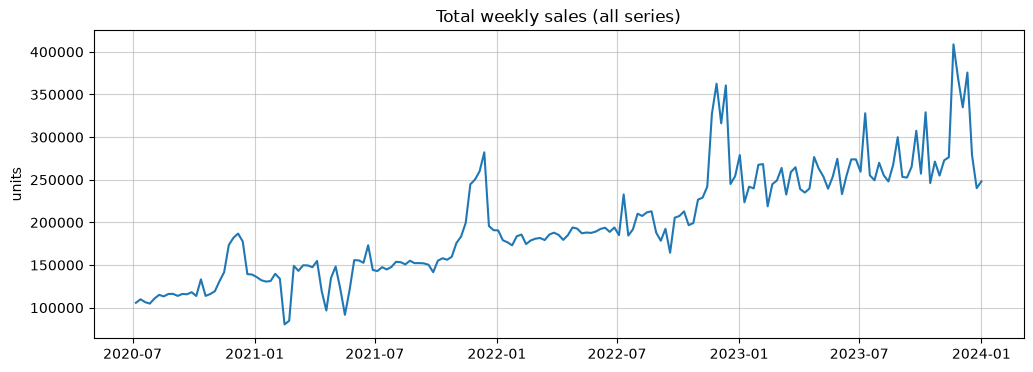

In [6]:
#Step2
#2a
total=hist.sum(axis=0)
print(total)

#2b. Graph

plt.figure(figsize=(12, 4))
plt.plot(total.index, total.values)
plt.title("Total weekly sales (all series)")
plt.ylabel("units")
plt.grid(alpha=0.6)
plt.show()


In [7]:
#2c
for y in [2020, 2021, 2022]:
    dec = total.loc[f"{y}-12-01":f"{y}-12-31"].tail(4)
    jm  = total.loc[f"{y+1}-01-01":f"{y+1}-03-31"]
    ratio = jm.mean() / dec.mean()
    print(y, len(dec), len(jm), round(ratio, 3))

2020 4 13 0.817
2021 4 13 0.781
2022 4 13 0.851


In [6]:
# Tiny test, nije chalao:
a = pd.Series([10, 20], index=["x", "y"])
b = pd.Series([2, 4],   index=["y", "z"])
print(a / b)     # x: NaN, y: 10.0, z: NaN  ← shudhu "y" mile

x     NaN
y    10.0
z     NaN
dtype: float64


Total series:      15,053
Never sold:        0
Sold from week 1:  2,224
Launched later:    12,829  (85.2% of all, 85.2% of sold)


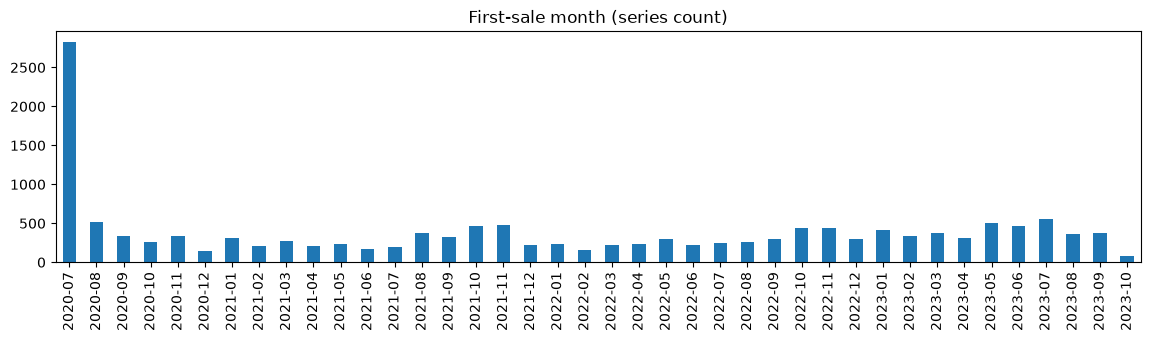

In [12]:

# Step 3a — when did each series start selling?
sold = hist.gt(0)
has_sale = sold.any(axis=1)

# idxmax gives the first True's date; all-zero rows would wrongly get week 1, so mask them.
first_sale = sold.idxmax(axis=1).where(has_sale)

first_week = hist.columns[0]
never_sold     = ~has_sale
from_start     = has_sale & first_sale.eq(first_week)
launched_later = has_sale & first_sale.gt(first_week)
assert never_sold.sum() + from_start.sum() + launched_later.sum() == len(hist)

print(f"Total series:      {len(hist):,}")
print(f"Never sold:        {never_sold.sum():,}")
print(f"Sold from week 1:  {from_start.sum():,}")
print(f"Launched later:    {launched_later.sum():,}  "
      f"({launched_later.mean():.1%} of all, {launched_later[has_sale].mean():.1%} of sold)")

first_sale.dt.to_period("M").value_counts().sort_index().plot(
    kind="bar", figsize=(14, 3), title="First-sale month (series count)")
plt.show()

In [13]:
# Step 3b — which series are silent now?
DEAD_WEEKS = 8

silent      = ~sold.iloc[:, -DEAD_WEEKS:].any(axis=1)
went_silent = has_sale & silent          # sold before, nothing in the last DEAD_WEEKS

print(f"Silent last {DEAD_WEEKS} weeks: {silent.sum():,} ({silent.mean():.1%})")
print(f"  of which sold before:   {went_silent.sum():,}")
print(f"  of which never sold:    {(silent & never_sold).sum():,}")



Silent last 8 weeks: 5,378 (35.7%)
  of which sold before:   5,378
  of which never sold:    0


In [15]:
# Step 3c — how long silent, and how much volume do they carry?

# Last sale date: reverse the columns, then idxmax finds the LAST True.
last_sale = sold.iloc[:, ::-1].idxmax(axis=1).where(has_sale)
weeks_silent = (hist.columns[-1] - last_sale).dt.days // 7

assert (weeks_silent >= DEAD_WEEKS).equals(silent)   # must match Step 3b

print(weeks_silent[silent].describe().round(1))
print(f"Silent 52+ weeks: {(weeks_silent >= 52).sum():,}")

last_year = hist.iloc[:, -52:].sum(axis=1)            # each series' last-52-week sales
print(f"Silent series' share of last-year volume: {last_year[silent].sum() / last_year.sum():.1%}")

count    5378.0
mean       47.9
std        42.3
min         8.0
25%        16.0
50%        30.0
75%        65.0
max       182.0
dtype: float64
Silent 52+ weeks: 1,726
Silent series' share of last-year volume: 2.2%
